# 00 — A 5-layer RNN and a 5-layer LSTM as compositions of elementary functions

A deep recurrent network looks complicated, but it is built from five elementary operations only:
**matrix product**, **addition**, **tanh**, **sigmoid** and the **element-wise product** ⊙.
This notebook builds a 5-layer RNN and a 5-layer LSTM out of those operations with NumPy, on numbers small enough to read,
and then checks that PyTorch (`nn.RNN`, `nn.LSTM`) and Keras (`SimpleRNN`, `LSTM`) compute exactly the same function.

Notation: a sequence has $T$ steps, each step a vector $x_t\in\mathbb{R}^F$; a layer has $H$ hidden units; layers are numbered $l=1..L$ with $L=5$;
$h^{(l)}_t$ is the hidden state of layer $l$ at step $t$. Vectors are row vectors, so a layer is written $xW$.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
np.set_printoptions(precision=4, suppress=True)
torch.manual_seed(0)
print("torch", torch.__version__, "| tensorflow", tf.__version__)

torch 2.14.1 | tensorflow 2.18.1


## 1. The elementary functions

| Function | Formula | Tiny example |
|---|---|---|
| matrix product | $(xW)_j=\sum_i x_iW_{ij}$ | $(1,2)\begin{pmatrix}1&0\\3&1\end{pmatrix}=(7,2)$ |
| addition | $a+b$ | $(7,2)+(0.5,-1)=(7.5,1)$ |
| tanh | $\tanh z=\frac{e^z-e^{-z}}{e^z+e^{-z}}\in(-1,1)$ | $\tanh(0.5)=0.4621$, $\tanh(3)=0.9951$ |
| sigmoid | $\sigma(z)=\frac1{1+e^{-z}}\in(0,1)$ | $\sigma(0)=0.5$, $\sigma(2)=0.8808$ |
| element-wise product | $(a\odot b)_i=a_ib_i$ | $(0.9,0.1)\odot(4,4)=(3.6,0.4)$ |

tanh squashes a value into $(-1,1)$: it is the *activation* of the RNN. sigmoid squashes into $(0,1)$: an LSTM uses it as a **gate**, a number that says how much of something to let through ($0.9$ keeps 90 %).
Their derivatives decide how well gradients flow: $\tanh'(z)=1-\tanh^2 z\le 1$ and $\sigma'(z)=\sigma(1-\sigma)\le 0.25$.

**Why these five and not others.**
- *matmul*: every hidden unit needs to see **every** input value, each with its own weight: unit $j$ computes $\sum_i x_iW_{ij}$. A matrix product does this for all units at once.
- *addition*: the cell has to merge two sources, the new input and its memory, so it adds them. Addition keeps both, and its derivative is 1, so gradients pass through it unchanged.
- *a nonlinearity (tanh, sigmoid)*: without one, depth is useless. Two linear layers collapse into one: $(xW_1)W_2=x(W_1W_2)$. Five layers without tanh would equal one matrix and could only draw straight decision boundaries.
- *tanh rather than ReLU in an RNN*: the same $W_h$ is applied at every step. ReLU has no upper bound, so if $W_h$ scales the state by 1.1, after 50 steps it has grown $1.1^{50}\approx117\times$. tanh clips every step back into $(-1,1)$, and it is zero-centred, so states can be positive or negative.
- *sigmoid for gates*: a gate must be a fraction between "block" (0) and "pass" (1). That is exactly the range of $\sigma$. tanh cannot serve as a gate because its range includes negative values.
- *⊙*: a gate controls each unit separately (keep unit 1, forget unit 2), so gate and content are multiplied position by position, not with a full matrix.

In [2]:
x = np.array([1., 2.]); W = np.array([[1., 0.], [3., 1.]]); b = np.array([0.5, -1.])
sigmoid = lambda z: 1 / (1 + np.exp(-z))
print("x W        =", x @ W)
print("x W + b    =", x @ W + b)
print("tanh(xW+b) =", np.tanh(x @ W + b))
print("sigmoid    =", sigmoid(np.array([0., 2.])))
print("gate ⊙     =", np.array([0.9, 0.1]) * np.array([4., 4.]))
print("tanh'(3) = 1 - tanh(3)^2 =", round(1 - np.tanh(3) ** 2, 4), "  <- a saturated unit passes almost no gradient")

x W        = [7. 2.]
x W + b    = [7.5 1. ]
tanh(xW+b) = [1.     0.7616]
sigmoid    = [0.5    0.8808]
gate ⊙     = [3.6 0.4]
tanh'(3) = 1 - tanh(3)^2 = 0.0099   <- a saturated unit passes almost no gradient


## 2. One RNN cell = a composition of three elementary functions

At step $t$ the cell mixes the new input with its own previous state:
$$h_t=\tanh\big(\underbrace{x_tW_x}_{\text{matmul}}+\underbrace{h_{t-1}W_h}_{\text{matmul}}+b\big),\qquad h_0=0 .$$
Written as a composition: $h_t = \tanh\circ\,\mathrm{add}\,(x_tW_x,\;h_{t-1}W_h,\;b)$.
The **same** $W_x, W_h, b$ are used at every step (weight sharing), so the cell is a function applied $T$ times, each time feeding its output back in.

**Why the formula looks like this.**
- $x_tW_x$ is *what is new* at step $t$ and $h_{t-1}W_h$ is *what was seen before*. Adding them makes the new state depend on both. That is the whole idea of a recurrent network: $h_t$ is a running summary of $x_1,\dots,x_t$.
- $h_0=0$ because before the first step nothing has been seen.
- **Why share weights across steps.** The rule for reading a word should not depend on where the word is: "not good" means the same at word 3 and at word 80, and a 2 % price drop means the same on any day. Sharing also keeps the size fixed: one $W_h$ serves sequences of any length. Separate weights for every step would multiply the parameters by $T$ and could not handle a longer sequence.
- Unrolled, $h_3=\tanh(x_3W_x+\tanh(x_2W_x+\tanh(x_1W_x+b)W_h+b)W_h+b)$. The first input reaches $h_3$ only through nested $W_h$ and tanh. That nesting causes the gradient problem in §4.

Tiny example with $F=2$ inputs and $H=2$ units:

In [3]:
Wx = np.array([[0.5, -0.3], [0.8, 0.2]]); Wh = np.array([[0.1, 0.4], [-0.2, 0.3]]); bh = np.array([0.0, 0.1])
xs = np.array([[1.0, 0.0], [0.5, 1.0], [0.0, -1.0]])      # T = 3 steps
h = np.zeros(2)
for t, xt in enumerate(xs, 1):
    a = xt @ Wx + h @ Wh + bh                              # matmul, matmul, add
    h = np.tanh(a)                                         # tanh
    print(f"t={t}: pre-activation a = {a},  h_{t} = tanh(a) = {h}")

t=1: pre-activation a = [ 0.5 -0.2],  h_1 = tanh(a) = [ 0.4621 -0.1974]
t=2: pre-activation a = [1.1357 0.2756],  h_2 = tanh(a) = [0.813  0.2689]
t=3: pre-activation a = [-0.7725  0.3058],  h_3 = tanh(a) = [-0.6484  0.2966]


## 3. Stacking five layers

A 5-layer RNN stacks five cells. Layer 1 reads the input sequence; layer $l$ reads the **hidden states of layer $l-1$** as its input sequence:
$$h^{(1)}_t=\tanh\big(x_tW^{(1)}_x+h^{(1)}_{t-1}W^{(1)}_h+b^{(1)}\big),\qquad
h^{(l)}_t=\tanh\big(h^{(l-1)}_tW^{(l)}_x+h^{(l)}_{t-1}W^{(l)}_h+b^{(l)}\big),\ l=2..5 .$$
The prediction uses the top layer at the last step: $\hat y=g\big(h^{(5)}_TW_y+b_y\big)$, with $g=\sigma$ for a yes/no label (review sentiment) or $g=$ identity for a number (stock volatility).

**As one composition.** Call $f^{(l)}$ the map that turns a whole sequence into the sequence of layer-$l$ states. Then
$$\hat y = g\circ\mathrm{last}\circ f^{(5)}\circ f^{(4)}\circ f^{(3)}\circ f^{(2)}\circ f^{(1)}\,(x_1,\dots,x_T),$$
and every $f^{(l)}$ is itself $T$ repetitions of matmul → add → tanh. The diagram shows the grid: information moves **up** (through layers, at the same step) and **right** (through time, in the same layer).

**Why stack layers.** Each layer re-reads the sequence produced by the layer below, so higher layers work on more abstract summaries:
- reviews: layer 1 reacts to single words ("good"), a middle layer to short phrases ("not good"), the top layer to the overall verdict.
- stocks: layer 1 sees one day's move, higher layers see patterns over weeks, such as a calm or a turbulent period.

One layer could in theory do all of this, but it would need many more units. Depth reuses the features already built below.

**Why only the last step of the top layer.** Through the recurrence, $h^{(5)}_T$ depends on every input $x_1..x_T$, so it already summarises the whole sequence. The task asks for one answer per sequence (one label per review, one forecast per window), so one vector is enough.

**Why $g=\sigma$ or identity.** For sentiment the output must be a probability in $(0,1)$, trained with cross-entropy. For volatility the output is a real number, trained with squared error, and squashing it would cap the forecast.

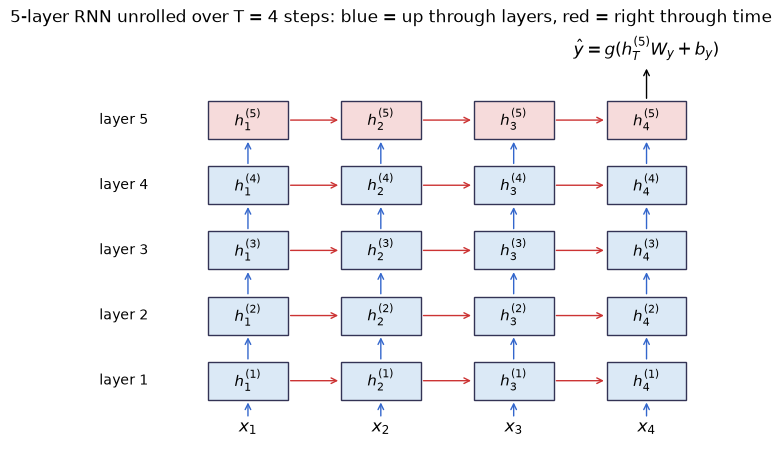

In [4]:
L, T_ = 5, 4
fig, ax = plt.subplots(figsize=(9, 5.5))
for l in range(L):
    for t in range(T_):
        ax.add_patch(plt.Rectangle((t * 2, l * 1.2), 1.2, 0.7, fc="#dbe9f6" if l < L - 1 else "#f6dbdb", ec="#335"))
        ax.text(t * 2 + 0.6, l * 1.2 + 0.35, f"$h^{{({l+1})}}_{{{t+1}}}$", ha="center", va="center", fontsize=11)
        if t < T_ - 1: ax.annotate("", (t * 2 + 2, l * 1.2 + 0.35), (t * 2 + 1.2, l * 1.2 + 0.35), arrowprops=dict(arrowstyle="->", color="#c33"))
        if l < L - 1: ax.annotate("", (t * 2 + 0.6, (l + 1) * 1.2), (t * 2 + 0.6, l * 1.2 + 0.7), arrowprops=dict(arrowstyle="->", color="#36c"))
    ax.text(-0.9, l * 1.2 + 0.35, f"layer {l+1}", ha="right", va="center")
for t in range(T_):
    ax.text(t * 2 + 0.6, -0.6, f"$x_{{{t+1}}}$", ha="center", fontsize=12)
    ax.annotate("", (t * 2 + 0.6, 0), (t * 2 + 0.6, -0.35), arrowprops=dict(arrowstyle="->", color="#36c"))
ax.text((T_ - 1) * 2 + 0.6, L * 1.2 + 0.35, "$\\hat y = g(h^{(5)}_T W_y + b_y)$", ha="center", fontsize=12)
ax.annotate("", ((T_ - 1) * 2 + 0.6, L * 1.2 + 0.15), ((T_ - 1) * 2 + 0.6, (L - 1) * 1.2 + 0.7), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-2.5, T_ * 2); ax.set_ylim(-1, L * 1.2 + 0.8); ax.axis("off")
ax.set_title("5-layer RNN unrolled over T = 4 steps: blue = up through layers, red = right through time")
plt.show()

### The 5-layer RNN by hand (NumPy), checked against PyTorch and Keras

Small sizes so the numbers stay readable: $F=3$ input features, $H=4$ units, $T=6$ steps, $L=5$ layers, batch of 2 sequences.
The weights are taken from a PyTorch `nn.RNN(3, 4, num_layers=5)` and copied into the hand-written version and into a Keras stack of five `SimpleRNN` layers.

Two naming details: PyTorch stores $W_x^\top$ (shape $H\times F$) as `weight_ih_l{k}` and has **two** biases `bias_ih`, `bias_hh` whose sum is our $b$; Keras stores $W_x$ (`kernel`, $F\times H$), $W_h$ (`recurrent_kernel`) and one bias.

In [5]:
F, H, T, L, B = 3, 4, 6, 5, 2
torch_rnn = nn.RNN(F, H, num_layers=L, batch_first=True)          # tanh by default
P = {k: v.detach().numpy().astype(np.float64) for k, v in torch_rnn.named_parameters()}
W = [dict(Wx=P[f"weight_ih_l{l}"].T, Wh=P[f"weight_hh_l{l}"].T, b=P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"]) for l in range(L)]

def rnn_layer(seq, Wx, Wh, b):
    """f^(l): sequence (B,T,in) -> sequence of states (B,T,H). Only matmul, add, tanh."""
    h = np.zeros((seq.shape[0], Wh.shape[0])); out = []
    for t in range(seq.shape[1]):
        h = np.tanh(seq[:, t] @ Wx + h @ Wh + b)
        out.append(h)
    return np.stack(out, 1)

def rnn_5layer(x):
    seq = x
    for l in range(L):                       # f^(5) ∘ ... ∘ f^(1)
        seq = rnn_layer(seq, **W[l])
    return seq

x = np.random.default_rng(0).normal(size=(B, T, F))
ours = rnn_5layer(x)
pt, _ = torch_rnn(torch.tensor(x, dtype=torch.float32))
km = keras.Sequential([layers.Input((T, F))] + [layers.SimpleRNN(H, return_sequences=True) for _ in range(L)])
for l, lay in enumerate(km.layers):
    lay.set_weights([W[l]["Wx"], W[l]["Wh"], W[l]["b"]])
kr = km(x.astype("float32")).numpy()
print("top-layer states h^(5)_t of sequence 0, by hand:\n", ours[0])
print(f"max |hand - PyTorch| = {np.abs(ours - pt.detach().numpy()).max():.2e}")
print(f"max |hand - Keras|   = {np.abs(ours - kr).max():.2e}")

I0000 00:00:1792130491.537129 24599716 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792130491.537189 24599716 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


top-layer states h^(5)_t of sequence 0, by hand:
 [[-0.5281  0.6066 -0.0721  0.3252]
 [-0.4431  0.4689 -0.0764  0.0933]
 [-0.5025  0.5906 -0.0932  0.197 ]
 [-0.4672  0.5651 -0.0562  0.0807]
 [-0.505   0.5967 -0.0782  0.1946]
 [-0.4929  0.5457 -0.047   0.0764]]
max |hand - PyTorch| = 6.79e-08
max |hand - Keras|   = 1.94e-07


### Parameters of a 5-layer RNN

Layer 1 maps $F\to H$, layers 2–5 map $H\to H$:
$$\underbrace{FH+H^2+H}_{\text{layer 1}}+\underbrace{4\,(H^2+H^2+H)}_{\text{layers 2–5}}+\underbrace{H+1}_{\text{head}} .$$
For $F=3$, $H=4$: $(12+16+4)+4(16+16+4)+5=32+144+5=181$. PyTorch adds the second bias vector, $L\cdot H=20$ more.
The count does not depend on $T$: a review of 10 words and one of 100 words use the same weights.

**Where each term comes from.**
- $W_x$ has shape $F\times H$ because each of the $H$ units has one weight per input feature. For layer 1 the inputs are the data features ($F$). For layers 2–5 the inputs are the $H$ states of the layer below, so the shape is $H\times H$.
- $W_h$ has shape $H\times H$ because each unit looks at the previous state of **all** $H$ units in its layer, its own included.
- $b$ gives one bias per unit ($H$). The head maps $H$ numbers to one output: $H$ weights + 1 bias.
- **Why PyTorch has more.** It keeps `bias_ih` and `bias_hh` separately (a convention from cuDNN). Only their sum enters the formula, so the model is identical; it just stores $H$ extra numbers per layer.

In [6]:
def rnn_params(F, H, L, two_bias=False):
    first = F * H + H * H + H * (2 if two_bias else 1)
    rest = (L - 1) * (H * H + H * H + H * (2 if two_bias else 1))
    return first + rest + H + 1
print("formula, Keras-style  :", rnn_params(F, H, L))
print("Keras stack (no head) :", km.count_params(), "+ head", H + 1, "=", km.count_params() + H + 1)
print("PyTorch nn.RNN + head :", sum(p.numel() for p in torch_rnn.parameters()) + H + 1, "= formula with two biases:", rnn_params(F, H, L, True))

formula, Keras-style  : 181
Keras stack (no head) : 176 + head 5 = 181
PyTorch nn.RNN + head : 201 = formula with two biases: 201


## 4. Why depth and length hurt a plain RNN: the gradient

Training needs $\partial L/\partial h^{(l)}_t$ for every layer and step. Going **back one step in time** multiplies the gradient by $W_h^\top\mathrm{diag}(1-h_t^2)$; going **down one layer** multiplies it by $W_x^\top\mathrm{diag}(1-h^2)$.
Each factor $1-h^2\le1$, so after many multiplications the signal usually **vanishes** (or, with large weights, explodes).

**Why the gradient is a product: the chain rule.** With $h_t=\tanh(a_t)$ and $a_t=x_tW_x+h_{t-1}W_h+b$:
$$\frac{\partial h_t}{\partial h_{t-1}}=\underbrace{\mathrm{diag}(1-h_t^2)}_{\tanh'}\;W_h^\top ,\qquad
\frac{\partial h_T}{\partial h_{t}}=\prod_{k=t+1}^{T}\mathrm{diag}(1-h_k^2)\,W_h^\top .$$
Reaching step $t$ from step $T$ takes $T-t$ such factors. Coming down from layer 5 to layer 1 adds four more of the same kind, with $W_x$ in place of $W_h$.

**Why it vanishes.** Every factor contains $1-h^2\le1$, and with typical initial weights each step shrinks the signal. A scalar picture: if each step multiplies by 0.6, then after 50 steps $0.6^{50}\approx8\times10^{-12}$. If each step multiplies by 1.2, the gradient instead explodes: $1.2^{50}\approx9{,}100$.

**Why it matters for training.** The weight update for the first words of a review is proportional to this gradient. If the gradient is $10^{-11}$, those words teach the model nothing, and the RNN effectively learns only from the last few steps. Explosion is handled by **gradient clipping** (clip-norm 1 in the dataset notebooks). Vanishing cannot be clipped away; it needs a different cell, the LSTM.

Below: the size of the gradient that reaches each layer and step of a freshly initialised 5-layer RNN, when the loss looks only at the last step of the top layer ($T=50$, $H=32$).

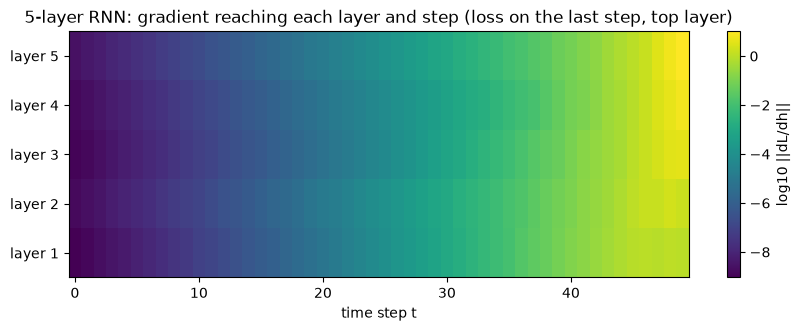

gradient reaching step 1, by layer: ['9.1e-10', '1.6e-09', '1.1e-09', '1.4e-09', '2.6e-09']
step 1 of layer 1 receives 8.7e-11 of the gradient at the top-right corner


In [7]:
def grad_map(kind, T=50, F=8, H=32, L=5, seed=0, forget_bias=1.0):
    """Unroll a 5-layer RNN/LSTM step by step with cells, so every h^(l)_t is on the gradient path.
    Loss = squared norm of the top layer's last state. Returns ||dL/dh^(l)_t|| as an (L, T) array."""
    torch.manual_seed(seed)
    cells = [(nn.RNNCell if kind == "RNN" else nn.LSTMCell)(F if l == 0 else H, H) for l in range(L)]
    if kind == "LSTM":                       # forget-gate bias (rows H..2H); Keras uses 1, PyTorch's default is 0
        for c in cells:
            c.bias_ih.data[H:2 * H] = forget_bias; c.bias_hh.data[H:2 * H] = 0.0
    x = torch.randn(16, T, F)
    hs, state = [[None] * T for _ in range(L)], [None] * L
    for t in range(T):
        inp = x[:, t]
        for l in range(L):
            out = cells[l](inp, state[l])
            state[l] = out
            h = out if kind == "RNN" else out[0]
            h.retain_grad(); hs[l][t] = h; inp = h
    hs[-1][-1].pow(2).sum().backward()
    return np.array([[hs[l][t].grad.norm().item() for t in range(T)] for l in range(L)])

g_rnn = grad_map("RNN")
plt.figure(figsize=(10, 3.2))
plt.imshow(np.log10(g_rnn + 1e-30), aspect="auto", cmap="viridis", origin="lower")
plt.colorbar(label="log10 ||dL/dh||"); plt.yticks(range(5), [f"layer {l+1}" for l in range(5)]); plt.xlabel("time step t")
plt.title("5-layer RNN: gradient reaching each layer and step (loss on the last step, top layer)"); plt.show()
print("gradient reaching step 1, by layer:", ["%.1e" % v for v in g_rnn[:, 0]])
print("step 1 of layer 1 receives %.1e of the gradient at the top-right corner" % (g_rnn[0, 0] / g_rnn[-1, -1]))

## 5. The LSTM cell: gates built from the same elementary functions

An LSTM adds a second state, the **cell** $c_t$, and three **gates** that decide what to forget, what to write and what to show.
Each gate is the RNN formula with a sigmoid instead of tanh:

| | Formula | Role |
|---|---|---|
| input gate | $i_t=\sigma(x_tW_i+h_{t-1}U_i+b_i)$ | how much new content to write |
| forget gate | $f_t=\sigma(x_tW_f+h_{t-1}U_f+b_f)$ | how much of the old cell to keep |
| candidate | $g_t=\tanh(x_tW_g+h_{t-1}U_g+b_g)$ | the new content |
| output gate | $o_t=\sigma(x_tW_o+h_{t-1}U_o+b_o)$ | how much of the cell to show |
| cell | $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ | memory, updated by **addition** |
| hidden | $h_t=o_t\odot\tanh(c_t)$ | output of the step |

Composition view: $(h_t,c_t)=\mathrm{LSTM}(x_t,h_{t-1},c_{t-1})$ uses matmul, add, sigmoid, tanh and ⊙, nothing else.

**Why it remembers.** The cell is updated by $c_t=f_t\odot c_{t-1}+\dots$. Going back one step multiplies the gradient by $f_t$ only (no squashing derivative, no weight matrix), so with $f_t\approx1$ the signal survives many steps.
Example: $f=0.9$, $c_{t-1}=2.0$, $i=0.5$, $g=0.6$: $c_t=0.9\cdot2.0+0.5\cdot0.6=1.8+0.3=2.1$.

**Why each piece is there.**
- *Gates see $x_t$ and $h_{t-1}$*: the decision to forget or write depends on context. After reading "not", the network should treat "good" differently, and only $h_{t-1}$ knows that "not" came before.
- *Candidate uses tanh*: new content can push a memory up or down, so it needs signed values in $(-1,1)$, just like the RNN.
- *Gates use sigmoid*: they are fractions (see §1).
- *Cell updated by addition*: $c_t=f_t\odot c_{t-1}+i_t\odot g_t$ keeps a copy of the old memory instead of re-squashing it through a matrix and tanh. So
$$\frac{\partial c_t}{\partial c_{t-1}}=\mathrm{diag}(f_t)\quad(\text{plus small indirect terms}).$$
Back over 50 steps with $f=0.97$: $0.97^{50}\approx0.22$. The RNN's $0.6^{50}\approx8\times10^{-12}$ is ten orders of magnitude smaller.
- *$h_t=o_t\odot\tanh(c_t)$*: the cell is a sum, so it can grow past 1, and tanh brings the output back into $(-1,1)$ for the next layer. The output gate lets the cell **hold** information without showing it until it is useful: a word read at step 5 can be released only at step 90.
- *The model learns the gates*: nobody sets $f_t$ by hand. Training adjusts $W_f, U_f, b_f$ so that $f_t\approx1$ where memory is useful (an early "but" that flips the review's meaning) and $f_t\approx0$ where it should reset.

In [8]:
def lstm_step(xt, h, c, Wk, Uk, bk):
    """One LSTM step from elementary functions. Wk, Uk, bk are dicts with keys i, f, g, o."""
    z = {k: xt @ Wk[k] + h @ Uk[k] + bk[k] for k in "ifgo"}            # four affine maps
    i, f, o = sigmoid(z["i"]), sigmoid(z["f"]), sigmoid(z["o"])        # gates in (0,1)
    g = np.tanh(z["g"])                                                # candidate in (-1,1)
    c = f * c + i * g                                                  # ⊙ and +
    h = o * np.tanh(c)
    return h, c, dict(i=i, f=f, g=g, o=o)

rng = np.random.default_rng(1)
Wk = {k: rng.normal(scale=0.5, size=(2, 2)) for k in "ifgo"}; Uk = {k: rng.normal(scale=0.5, size=(2, 2)) for k in "ifgo"}
bk = {k: np.zeros(2) for k in "ifgo"}; bk["f"] = np.ones(2)                # forget bias 1: start by remembering
h = c = np.zeros(2)
for t, xt in enumerate(xs, 1):
    h, c, gates = lstm_step(xt, h, c, Wk, Uk, bk)
    print(f"t={t}: f={gates['f']} i={gates['i']} o={gates['o']}  ->  c={c}  h={h}")

t=1: f=[0.8104 0.7726] i=[0.5431 0.6013] o=[0.409  0.4796]  ->  c=[0.0979 0.0878]  h=[0.0399 0.042 ]
t=2: f=[0.7281 0.805 ] i=[0.5587 0.3876] o=[0.407  0.5596]  ->  c=[0.0979 0.1837]  h=[0.0397 0.1017]
t=3: f=[0.7916 0.6803] i=[0.4491 0.6531] o=[0.5873 0.413 ]  ->  c=[ 0.043  -0.0844]  h=[ 0.0252 -0.0348]


### The 5-layer LSTM by hand, checked against PyTorch and Keras

Stacking works exactly as for the RNN: layer $l$ reads the hidden states $h^{(l-1)}_t$ of the layer below; every layer has its own cell $c^{(l)}_t$.
Both frameworks store the four gates side by side in one matrix of width $4H$, in the order **i, f, g, o** (Keras calls $g$ "c"); PyTorch again keeps two biases.

**Why one matrix of width $4H$.** All four gates use the same inputs $(x_t,h_{t-1})$. Concatenating their weights turns four small products into one large one, which a GPU or CPU computes faster. The result is then split into four blocks of $H$ columns. The order **i, f, g, o** is only a storage convention, but it must match when weights are copied between frameworks, which is why the check above copies block by block.

In [9]:
torch_lstm = nn.LSTM(F, H, num_layers=L, batch_first=True)
P = {k: v.detach().numpy().astype(np.float64) for k, v in torch_lstm.named_parameters()}
def split4(M): return dict(zip("ifgo", np.split(M, 4, axis=-1)))
WL = [dict(W=split4(P[f"weight_ih_l{l}"].T), U=split4(P[f"weight_hh_l{l}"].T), b=split4(P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"])) for l in range(L)]

def lstm_5layer(x):
    seq = x
    for l in range(L):
        h = np.zeros((x.shape[0], H)); c = np.zeros_like(h); out = []
        for t in range(seq.shape[1]):
            h, c, _ = lstm_step(seq[:, t], h, c, WL[l]["W"], WL[l]["U"], WL[l]["b"])
            out.append(h)
        seq = np.stack(out, 1)
    return seq

ours = lstm_5layer(x)
pt, _ = torch_lstm(torch.tensor(x, dtype=torch.float32))
kl = keras.Sequential([layers.Input((T, F))] + [layers.LSTM(H, return_sequences=True) for _ in range(L)])
for l, lay in enumerate(kl.layers):
    lay.set_weights([P[f"weight_ih_l{l}"].T, P[f"weight_hh_l{l}"].T, P[f"bias_ih_l{l}"] + P[f"bias_hh_l{l}"]])
print(f"max |hand - PyTorch| = {np.abs(ours - pt.detach().numpy()).max():.2e}")
print(f"max |hand - Keras|   = {np.abs(ours - kl(x.astype('float32')).numpy()).max():.2e}")

max |hand - PyTorch| = 3.60e-08


max |hand - Keras|   = 8.88e-08


### Parameters of a 5-layer LSTM

Each layer has four copies of the RNN's weights (one per gate):
$$4(FH+H^2+H)+4\cdot4(H^2+H^2+H)+H+1 .$$
For $F=3$, $H=4$: $4\cdot32+4\cdot4\cdot36+5=128+576+5=709$, about 4× the RNN's 181.

**Why exactly 4×.** Each of the four blocks (i, f, g, o) has the same shape as one RNN layer: an input matrix, a recurrent matrix and a bias. The cell update and $h_t=o\odot\tanh c_t$ add no parameters, because they only combine the four results with ⊙ and +.

**What it costs.** Each step does four times the matrix work of an RNN step, so an LSTM epoch takes longer. The extra parameters buy controlled memory, not a bigger model of the same kind. In the dataset notebooks the RNN is not simply given 4× more units to compensate, because then the comparison would change the size and the architecture at the same time.

In [10]:
def lstm_params(F, H, L, two_bias=False):
    nb = 2 if two_bias else 1
    return 4 * (F * H + H * H + nb * H) + (L - 1) * 4 * (2 * H * H + nb * H) + H + 1
print("formula, Keras-style  :", lstm_params(F, H, L), "  Keras stack + head:", kl.count_params() + H + 1)
print("PyTorch nn.LSTM + head:", sum(p.numel() for p in torch_lstm.parameters()) + H + 1, "= formula with two biases:", lstm_params(F, H, L, True))
print("\nsizes used in the dataset notebooks (5 layers):")
print(f"  reviews, input = 64-d word embedding, H = 64: RNN {rnn_params(64, 64, 5):,}  LSTM {lstm_params(64, 64, 5):,}  (+ embedding 20,000 x 64)")
print(f"  stocks,  input = 4 features,          H = 32: RNN {rnn_params(4, 32, 5):,}  LSTM {lstm_params(4, 32, 5):,}")

formula, Keras-style  : 709   Keras stack + head: 709
PyTorch nn.LSTM + head: 789 = formula with two biases: 789

sizes used in the dataset notebooks (5 layers):
  reviews, input = 64-d word embedding, H = 64: RNN 41,345  LSTM 165,185  (+ embedding 20,000 x 64)
  stocks,  input = 4 features,          H = 32: RNN 9,537  LSTM 38,049


## 6. Gradient flow: LSTM against RNN

The same experiment as in §4, now for a 5-layer LSTM, with two settings of the forget-gate bias. With bias 1 (Keras's default, $f_t\approx\sigma(1)=0.73$ at the start) the additive cell path carries far more gradient back to early steps and low layers than the RNN; with bias 0 (PyTorch's default, $f_t\approx0.5$) the cell forgets half of itself at every step and the advantage disappears at initialisation. The dataset notebooks therefore set the forget bias to 1 in PyTorch too, so both frameworks start alike.

**Why bias 1 helps.** At initialisation $f_t\approx\sigma(b_f)$, and the signal passing back through the cell is roughly $f^{T}$:
- bias 0: $\sigma(0)=0.5$, $0.5^{50}\approx9\times10^{-16}$. The cell starts out forgetting everything, as badly as the RNN.
- bias 1: $\sigma(1)=0.73$, $0.73^{50}\approx1.6\times10^{-7}$, about $10^{8}$ times larger. Training then has a signal to push $f$ toward 1 where memory pays off.

The idea is to start the network remembering and let it learn what to forget. If it starts out forgetting, it can never discover what was worth remembering, because no gradient reaches the early steps.

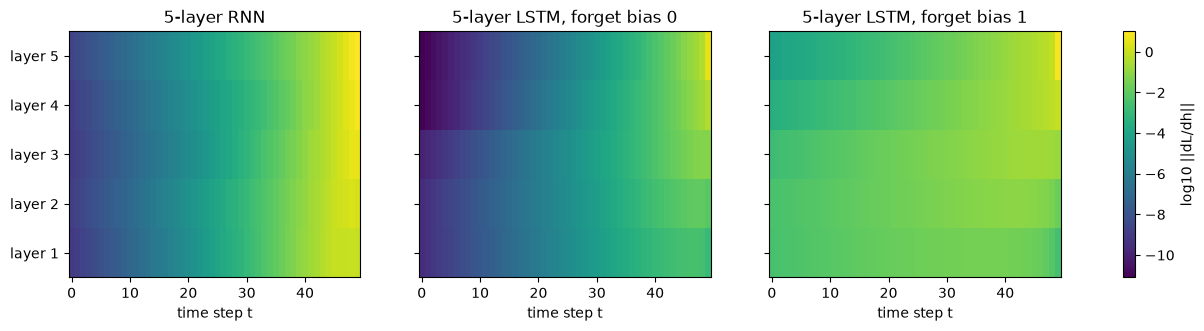

RNN                   : step 1 of layer 1 receives 8.7e-11 of the top-right gradient
LSTM, forget bias 0   : step 1 of layer 1 receives 9.4e-11 of the top-right gradient
LSTM, forget bias 1   : step 1 of layer 1 receives 4.5e-04 of the top-right gradient


In [11]:
g_lstm = grad_map("LSTM", forget_bias=1.0)
g_lstm0 = grad_map("LSTM", forget_bias=0.0)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.2), sharey=True)
maps = [(g_rnn, "RNN"), (g_lstm0, "LSTM, forget bias 0"), (g_lstm, "LSTM, forget bias 1")]
vmin = min(np.log10(g.min() + 1e-30) for g, _ in maps); vmax = max(np.log10(g.max()) for g, _ in maps)
for a, (g, name) in zip(ax, maps):
    im = a.imshow(np.log10(g + 1e-30), aspect="auto", cmap="viridis", origin="lower", vmin=vmin, vmax=vmax)
    a.set_title(f"5-layer {name}"); a.set_xlabel("time step t")
ax[0].set_yticks(range(5)); ax[0].set_yticklabels([f"layer {l+1}" for l in range(5)])
fig.colorbar(im, ax=ax, label="log10 ||dL/dh||"); plt.show()
for g, name in maps:
    print(f"{name:22s}: step 1 of layer 1 receives {g[0, 0] / g[-1, -1]:.1e} of the top-right gradient")

## 7. Summary

| | 5-layer RNN | 5-layer LSTM |
|---|---|---|
| elementary functions | matmul, add, tanh | matmul, add, tanh, sigmoid, ⊙ |
| state per layer | $h_t$ | $h_t$ and cell $c_t$ |
| one step | $h_t=\tanh(x_tW_x+h_{t-1}W_h+b)$ | 3 gates + candidate, $c_t=f\odot c_{t-1}+i\odot g$, $h_t=o\odot\tanh c_t$ |
| parameters per layer | $FH+H^2+H$ | $4(FH+H^2+H)$ |
| gradient back one step | $\times W_h^\top\mathrm{diag}(1-h^2)$: shrinks | through $c$: $\times f_t$, kept when $f_t\approx1$ |
| PyTorch / Keras | `nn.RNN(num_layers=5)` / 5 × `SimpleRNN` | `nn.LSTM(num_layers=5)` / 5 × `LSTM` |

The hand-written versions matched PyTorch and Keras to float32 precision, so the frameworks compute exactly the compositions written above.
The dataset notebooks use these two architectures on review comments and on stock prices.

**Which one to choose, and why.** The LSTM's advantage is the cell path, which only pays off when the answer depends on information far back in the sequence. For short sequences, or when the last few steps carry most of the signal, a plain RNN can do nearly as well at a quarter of the cost. The two dataset notebooks test exactly this. The reviews (up to 100 words, negatives often explained at length) need long memory. Stock volatility depends mostly on the recent weeks.